# RehaPiano – hypotézy, testy a normálne hodnoty podľa veku

**Zadanie:** *Pripraviť štatistickú analýzu – stanoviť hypotézy a urobiť testy štatistickej významnosti rozdielu medzi
zdravými a chorými. Urobiť analýzu zmien parametrov u zdravých ľudí s vekom, stanoviť „normálne" hodnoty a rozsahy podľa
dekád.*

Tento súbor je stručné zhrnutie: **každá hypotéza je napísaná jednoducho, pod ňou je graf a výsledok testu.**
Podrobné tabuľky sú v `notebooks/exact_force/statisticka_analyza_exact_force.ipynb` a
`notebooks/rhythm/statisticka_analyza_rytmus.ipynb`.

**Dva testy:**
- **EXACT_FORCE** – osoba drží všetkými prstami rovnomernú silu (4 pokusy po 16 s).
- **RYTMUS** – osoba rytmicky stláča obomi rukami naraz (4 pokusy po 31 s, 1. pokus je nácvik).

**Kto je v dátach:** zdraví, ktorí v dotazníku neuviedli žiadne ťažkosti s rukami, a všetci pacienti.

**Ako sú hypotézy testované:** pacienti sú starší ako zdraví, a preto ich **porovnávame vždy len s rovnako
starými zdravými – v tej istej dekáde** (20–29 so 20–29, 60–69 so 60–69, …). Rozdiel, ktorý nájdeme, teda
nie je spôsobený vekom.
- V každej dekáde porovnáme hodnoty zdravých a pacientov (Mann-Whitneyho test).
- Výsledky všetkých dekád spojíme do jedného testu (**van Elterenov test** = Mann-Whitneyho test rozdelený podľa dekád).
- **p < 0,05** = rozdiel nie je náhoda. P-hodnoty sú opravené na počet testovaných parametrov (Holmova korekcia).
- V súbore sú uvedené **len potvrdené hypotézy** (p < 0,05 a rozdiel v očakávanom smere).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

# ROOT = repository root (package src/rehapiano, data/, outputs/)
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "rehapiano").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from rehapiano.common.config import AGE_CATEGORY_LABELS, OLDER_AGE
from rehapiano.common.stats.models import ols
from rehapiano.common.stats.tests import holm_adjust
from rehapiano.exact_force.parameters import EXPECTED_DIRECTION as EF_DIRECTION, PARAMETERS as EF_PARAMETERS
from rehapiano.rhythm.parameters import EXPECTED_DIRECTION as RH_DIRECTION, PARAMETERS as RH_PARAMETERS
from rehapiano.exact_force.config import ANALYSIS_OUTPUT_DIR as EF_OUT, EF_OUTPUT_DIR, PRIMARY_CONTROL_STEP_ID, PATIENT_STEP_IDS
from rehapiano.rhythm.config import ANALYSIS_OUTPUT_DIR as RH_OUT

FIG = Path.cwd() / "figures" / "hypotezy_a_normy"; FIG.mkdir(parents=True, exist_ok=True)


def load(out):
    tables = {path.stem: pd.read_csv(path) for path in sorted(out.glob("*.csv"))}
    people = tables["people"]
    people["decade"] = pd.Categorical(people["decade"], AGE_CATEGORY_LABELS, ordered=True)
    tables["main"] = people.loc[people["screened"]].reset_index(drop=True)
    return tables


TESTS = {"EXACT_FORCE": load(EF_OUT), "RYTMUS": load(RH_OUT)}

GROUP_COLORS = {"control": "#2a78d6", "patient": "#eb6834"}
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "axes.titleweight": "bold", "axes.titlesize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10,
})
SK_GROUP = {"control": "Zdraví", "patient": "Pacienti"}
GROUPS = ["control", "patient"]

# The hypotheses: (test, parameter, short title, hypothesis in plain words, axis label).
HYPOTHESES = [('EXACT_FORCE',
  'tremor_amplitude',
  'Silnejšie chvenie prstov',
  'Keď človek drží prstami rovnakú silu, prsty sa jemne a rýchlo chvejú (4–15 Hz). Predpokladáme, že u pacientov je '
  'toto chvenie silnejšie ako u zdravých.',
  'amplitúda trasu prstov (4–15 Hz) [×10⁻⁵]'),
 ('EXACT_FORCE',
  'movement_amplitude',
  'Sila viac kolíše',
  'Ani zdravý človek neudrží silu úplne rovnú – sila sa jemne mení v čase hore a dole, lebo človek chce udržať silu '
  'na jednej úrovni a stále ju dorovnáva (pomalé zmeny 0–4 Hz; rýchle chvenie 4–15 Hz je v H1). Predpokladáme, že '
  'pacientom sila takto kolíše viac – udržia ju menej stabilne.',
  'kolísanie sily okolo cieľovej úrovne (0–4 Hz) [×10⁻⁵]'),
 ('EXACT_FORCE',
  'finger_spread',
  'Väčšie rozdiely medzi prstami',
  'U zdravého človeka sa všetky prsty jednej ruky pri držaní sily správajú podobne. Predpokladáme, že u pacientov sa '
  'jednotlivé prsty tej istej ruky správajú výrazne odlišne – pomer chvenia a kolísania sily sa medzi prstami líši '
  'viac ako u zdravých.',
  'rozdielnosť správania prstov jednej ruky (CV)'),
 ('EXACT_FORCE',
  'tremor_balance',
  'Jedna ruka sa chveje viac',
  'U zdravých sa obe ruky chvejú približne rovnako. Ochorenie často postihne viac jednu stranu tela, preto '
  'predpokladáme, že u pacientov sa jedna ruka chveje výrazne viac ako druhá.',
  'chvenie pokojnejšej / chvenie horšej ruky (1 = rovnaké)'),
 ('EXACT_FORCE',
  'mean_force',
  'Menšia sila prstov',
  'Úlohou je tlačiť prstami predpísanou silou. Predpokladáme, že pacienti majú slabšie prsty a tlačia menšou silou '
  'ako zdraví.',
  'sila prstov [×10⁻³]'),
 ('EXACT_FORCE',
  'tremor_frequency_hz',
  'Pomalšie chvenie',
  'Chorobný tras (napr. pri Parkinsonovej chorobe) je pomalý, okolo 4–6 Hz, zdravé chvenie je rýchlejšie. '
  'Predpokladáme, že prsty pacientov sa chvejú pomalšie (s nižšou frekvenciou) ako prsty zdravých.',
  'frekvencia chvenia [Hz]'),
 ('RYTMUS',
  'press_rate_hz',
  'Pomalšie stláčanie',
  'V rytmickom teste človek opakovane stláča prstami oboch rúk naraz. Predpokladáme, že pacienti sú pomalší a stihnú '
  'za sekundu menej stlačení ako zdraví.',
  'počet stlačení za sekundu'),
 ('RYTMUS',
  'balance',
  'Jedna ruka tlačí slabšie',
  'Pri stláčaní obomi rukami naraz tlačia u zdravého človeka obe ruky podobne silno. Predpokladáme, že u pacientov '
  'tlačí jedna ruka výrazne slabšie ako druhá.',
  'pomer sily slabšej a silnejšej ruky'),
 ('RYTMUS',
  'sync_lag_ms',
  'Jedna ruka zaostáva',
  'Obe ruky majú stlačiť v rovnakom okamihu. Predpokladáme, že u pacientov jedna ruka zaostáva za druhou, teda čas '
  'medzi stlačením ľavou a pravou rukou je dlhší ako u zdravých.',
  'časový rozdiel stlačenia ľavej a pravej ruky [ms]'),
 ('RYTMUS',
  'interval_cv',
  'Nepravidelný rytmus',
  'Zdravý človek stláča v pravidelnom rytme – časy medzi stlačeniami sú takmer rovnaké. Predpokladáme, že pacienti '
  'stláčajú nepravidelnejšie, teda časy medzi stlačeniami sa u nich viac menia.',
  'nepravidelnosť rytmu (CV intervalov)')]
SCALE = {"tremor_amplitude": 1e5, "movement_amplitude": 1e5, "mean_force": 1e3}
LOG_AXIS = {"tremor_amplitude", "movement_amplitude"}
LABEL = {p: label for _, p, _, _, label in HYPOTHESES}
TEST_OF = {p: test for test, p, *_ in HYPOTHESES}
scaled = lambda p, v: v * SCALE.get(p, 1)


def fmt(value, digits=2):
    # Slovak decimal comma
    return f"{value:.{digits}g}".replace(".", ",") if abs(value) < 0.01 and value != 0 else f"{value:.{digits}f}".replace(".", ",")


def pval(p):
    return "< 0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")


def peq(p):
    # "= 0,012" or "< 0,001"
    return pval(p) if p < 0.001 else f"= {pval(p)}"


def log_axis(ax):
    # log scale with plain numbers (2, 5, 10) instead of 2×10⁰
    ax.set_yscale("log")
    label = lambda v: f"{v:g}".replace(".", ",")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: label(v)))
    ax.yaxis.set_minor_formatter(mticker.FuncFormatter(lambda v, _: label(v) if f"{v:.0e}"[0] in "25" else ""))


def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()


def van_elteren(frame, column):
    """Mann-Whitney within every decade, combined over decades (van Elteren). Returns z (> 0 = patients higher), p."""
    numerator, variance = 0.0, 0.0
    for _, d in frame.dropna(subset=[column]).groupby("decade", observed=True):
        m, n = int(d.patient.sum()), int((d.patient == 0).sum())
        if m == 0 or n == 0:
            continue
        N = m + n
        ranks = stats.rankdata(d[column])
        _, ties = np.unique(d[column], return_counts=True)
        weight = 1 / (N + 1)
        numerator += weight * (ranks[d.patient.values == 1].sum() - m * (N + 1) / 2)
        variance += weight ** 2 * m * n / 12 * ((N + 1) - (ties ** 3 - ties).sum() / (N * (N - 1)))
    z = numerator / np.sqrt(variance)
    return z, 2 * stats.norm.sf(abs(z))


# All parameters of each test are tested (Holm over them); the file shows the confirmed hypotheses.
PARAMETERS = {"EXACT_FORCE": (EF_PARAMETERS, EF_DIRECTION), "RYTMUS": (RH_PARAMETERS, RH_DIRECTION)}
rows = []
for test, (parameters, direction) in PARAMETERS.items():
    m = TESTS[test]["main"]
    result = pd.DataFrame([(test, p, *van_elteren(m, p), direction[p]) for p in parameters],
                          columns=["test", "parameter", "z", "p", "expected"])
    result["p_holm"] = holm_adjust(result.p.values)
    rows.append(result)
DECADE_TESTS = pd.concat(rows).set_index("parameter")
DECADE_TESTS["confirmed"] = (DECADE_TESTS.p_holm < 0.05) & (np.sign(DECADE_TESTS.z) == DECADE_TESTS.expected)
CONFIRMED = [h for h in HYPOTHESES if DECADE_TESTS.loc[h[1], "confirmed"]]
NOT_CONFIRMED = [h for h in HYPOTHESES if not DECADE_TESTS.loc[h[1], "confirmed"]]


def decade_rows(test, p, min_size=1):
    """Per decade: n and median of healthy and patients, Mann-Whitney p if both groups have >= 3 people."""
    m = TESTS[test]["main"]
    out = []
    for decade in AGE_CATEGORY_LABELS:
        h = scaled(p, m.loc[(m.decade == decade) & (m.group == "control"), p].dropna())
        s = scaled(p, m.loc[(m.decade == decade) & (m.group == "patient"), p].dropna())
        if len(h) < min_size or len(s) < min_size:
            continue
        out.append({"dekáda": decade, "zdraví n": len(h), "zdraví medián": h.median(),
                    "pacienti n": len(s), "pacienti medián": s.median(),
                    "p v dekáde": stats.mannwhitneyu(s, h).pvalue if min(len(h), len(s)) >= 3 else np.nan})
    return pd.DataFrame(out)


for test, t in TESTS.items():
    m = t["main"]
    print(f"{test}: zdraví {int((m.group == 'control').sum())}, pacienti {int((m.group == 'patient').sum())}")

EXACT_FORCE: zdraví 135, pacienti 48
RYTMUS: zdraví 135, pacienti 48


## Prehľad potvrdených hypotéz

In [2]:
rows = []
for k, (test, p, title, text, _) in enumerate(CONFIRMED, 1):
    d = decade_rows(test, p, min_size=2)
    expected = DECADE_TESTS.loc[p, "expected"]
    worse = int((np.sign(d["pacienti medián"] - d["zdraví medián"]) == expected).sum())
    rows.append({"": f"H{k}", "hypotéza": title, "test": test,
                 "pacienti horší v dekádach": f"{worse} z {len(d)}", "p (po dekádach)": pval(DECADE_TESTS.loc[p, "p_holm"])})
display(pd.DataFrame(rows).style.hide(axis="index").set_properties(**{"text-align": "left"}))
display(Markdown("*Pacienti horší v dekádach = v koľkých dekádach (s aspoň 2 zdravými a 2 pacientmi) má medián "
                 "pacientov hodnotu v smere hypotézy.*"))

,hypotéza,test,pacienti horší v dekádach,p (po dekádach)
H1,Silnejšie chvenie prstov,EXACT_FORCE,6 z 6,"< 0,001"
H2,Sila viac kolíše,EXACT_FORCE,6 z 6,"< 0,001"
H3,Menšia sila prstov,EXACT_FORCE,4 z 6,"0,004"
H4,Pomalšie stláčanie,RYTMUS,6 z 6,"0,005"
H5,Jedna ruka tlačí slabšie,RYTMUS,4 z 6,"0,002"
H6,Jedna ruka zaostáva,RYTMUS,6 z 6,"0,010"


*Pacienti horší v dekádach = v koľkých dekádach (s aspoň 2 zdravými a 2 pacientmi) má medián pacientov hodnotu v smere hypotézy.*

## 1. Rozdiel medzi zdravými a pacientmi v rovnakom veku

Graf: pre každú dekádu vedľa seba **zdraví (modrá)** a **pacienti (oranžová)**; bod = jedna osoba,
čiara = medián skupiny v dekáde. Pod grafom je tabuľka po dekádach (p v dekáde sa počíta len pri ≥ 3 osobách
v oboch skupinách – v malých dekádach je skôr orientačné).

### H1: Silnejšie chvenie prstov

Keď človek drží prstami rovnakú silu, prsty sa jemne a rýchlo chvejú (4–15 Hz). Predpokladáme, že u pacientov je toto chvenie silnejšie ako u zdravých.

*Test EXACT_FORCE.*

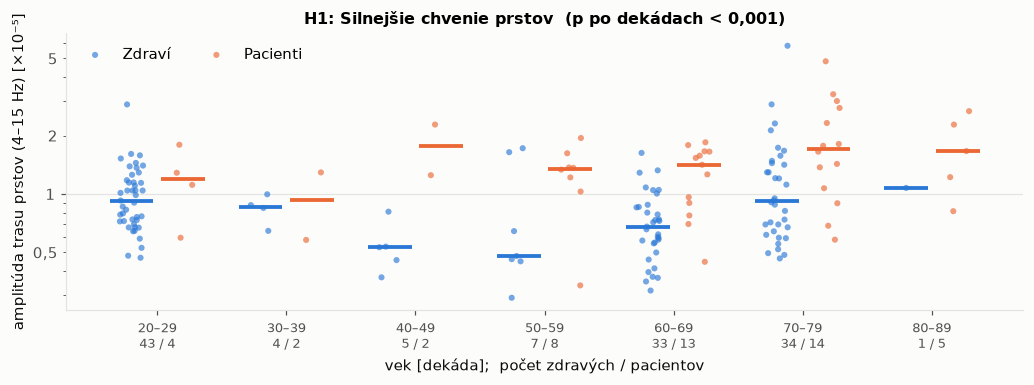

dekáda,zdraví n,zdraví medián,pacienti n,pacienti medián,p v dekáde
20–29,43,"0,93",4,"1,20","0,406"
30–39,4,"0,86",2,"0,94",–
40–49,5,"0,53",2,"1,77",–
50–59,7,"0,48",8,"1,35","0,281"
60–69,33,"0,68",13,"1,42","< 0,001"
70–79,34,"0,92",14,"1,71","0,011"
80–89,1,"1,07",5,"1,66",–


**Výsledok: ✅ potvrdená** – pri porovnaní rovnako starých ľudí p < 0,001; pacienti sú horší v 6 z 6 dekád.

### H2: Sila viac kolíše

Ani zdravý človek neudrží silu úplne rovnú – sila sa jemne mení v čase hore a dole, lebo človek chce udržať silu na jednej úrovni a stále ju dorovnáva (pomalé zmeny 0–4 Hz; rýchle chvenie 4–15 Hz je v H1). Predpokladáme, že pacientom sila takto kolíše viac – udržia ju menej stabilne.

*Test EXACT_FORCE.*

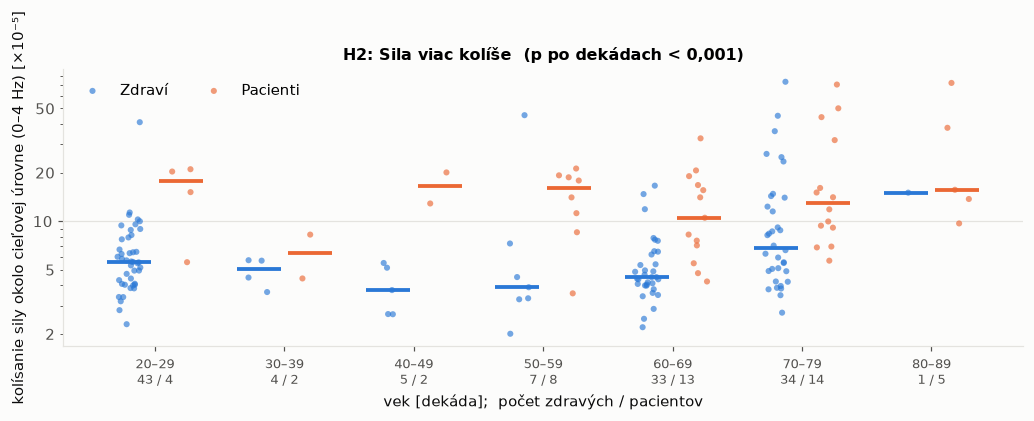

dekáda,zdraví n,zdraví medián,pacienti n,pacienti medián,p v dekáde
20–29,43,"5,59",4,"17,74","0,017"
30–39,4,"5,08",2,"6,34",–
40–49,5,"3,74",2,"16,47",–
50–59,7,"3,90",8,"15,96","0,054"
60–69,33,"4,50",13,"10,51","< 0,001"
70–79,34,"6,84",14,"12,96","0,011"
80–89,1,"15,03",5,"15,66",–


**Výsledok: ✅ potvrdená** – pri porovnaní rovnako starých ľudí p < 0,001; pacienti sú horší v 6 z 6 dekád.

### H3: Menšia sila prstov

Úlohou je tlačiť prstami predpísanou silou. Predpokladáme, že pacienti majú slabšie prsty a tlačia menšou silou ako zdraví.

*Test EXACT_FORCE.*

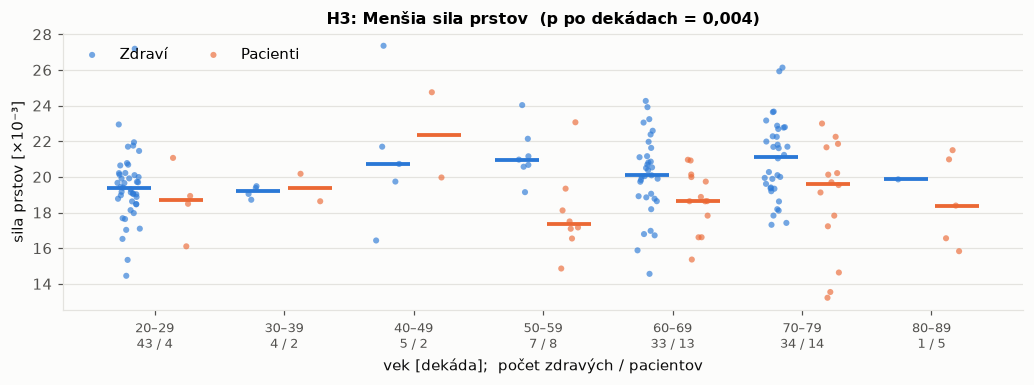

dekáda,zdraví n,zdraví medián,pacienti n,pacienti medián,p v dekáde
20–29,43,"19,39",4,"18,71","0,427"
30–39,4,"19,21",2,"19,40",–
40–49,5,"20,72",2,"22,36",–
50–59,7,"20,97",8,"17,33","0,014"
60–69,33,"20,09",13,"18,64","0,034"
70–79,34,"21,13",14,"19,62","0,055"
80–89,1,"19,86",5,"18,39",–


**Výsledok: ✅ potvrdená** – pri porovnaní rovnako starých ľudí p = 0,004; pacienti sú horší v 4 z 6 dekád.

### H4: Pomalšie stláčanie

V rytmickom teste človek opakovane stláča prstami oboch rúk naraz. Predpokladáme, že pacienti sú pomalší a stihnú za sekundu menej stlačení ako zdraví.

*Test RYTMUS.*

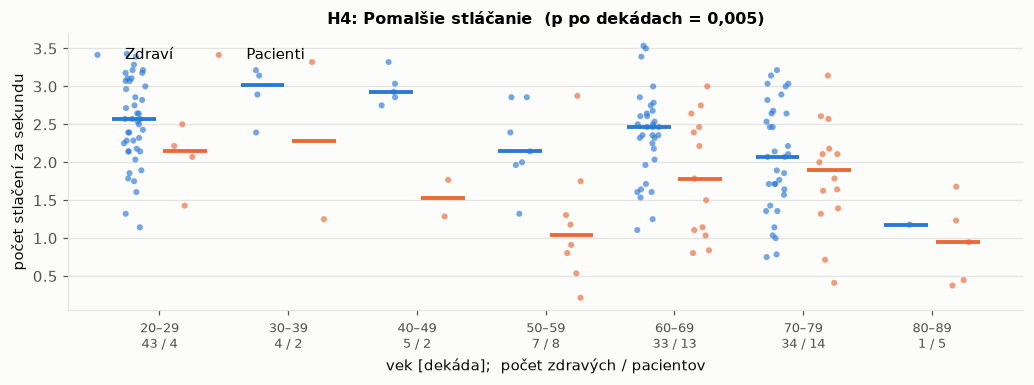

dekáda,zdraví n,zdraví medián,pacienti n,pacienti medián,p v dekáde
20–29,43,"2,57",4,"2,14","0,093"
30–39,4,"3,02",2,"2,29",–
40–49,5,"2,93",2,"1,53",–
50–59,7,"2,14",8,"1,04","0,024"
60–69,33,"2,46",13,"1,79","0,052"
70–79,34,"2,07",14,"1,89","0,370"
80–89,1,"1,18",5,"0,95",–


**Výsledok: ✅ potvrdená** – pri porovnaní rovnako starých ľudí p = 0,005; pacienti sú horší v 6 z 6 dekád.

### H5: Jedna ruka tlačí slabšie

Pri stláčaní obomi rukami naraz tlačia u zdravého človeka obe ruky podobne silno. Predpokladáme, že u pacientov tlačí jedna ruka výrazne slabšie ako druhá.

*Test RYTMUS.*

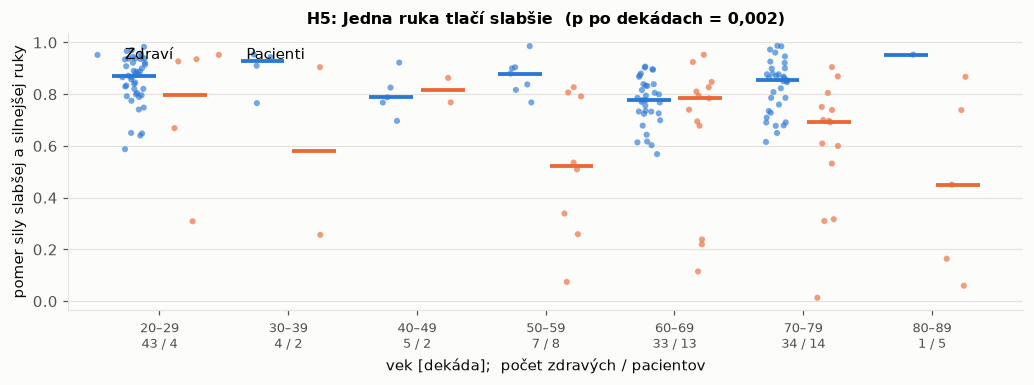

dekáda,zdraví n,zdraví medián,pacienti n,pacienti medián,p v dekáde
20–29,43,"0,87",4,"0,80","0,543"
30–39,4,"0,93",2,"0,58",–
40–49,5,"0,79",2,"0,82",–
50–59,7,"0,88",8,"0,52","0,004"
60–69,33,"0,78",13,"0,78","0,608"
70–79,34,"0,85",14,"0,69","0,001"
80–89,1,"0,95",5,"0,45",–


**Výsledok: ✅ potvrdená** – pri porovnaní rovnako starých ľudí p = 0,002; pacienti sú horší v 4 z 6 dekád.

### H6: Jedna ruka zaostáva

Obe ruky majú stlačiť v rovnakom okamihu. Predpokladáme, že u pacientov jedna ruka zaostáva za druhou, teda čas medzi stlačením ľavou a pravou rukou je dlhší ako u zdravých.

*Test RYTMUS.*

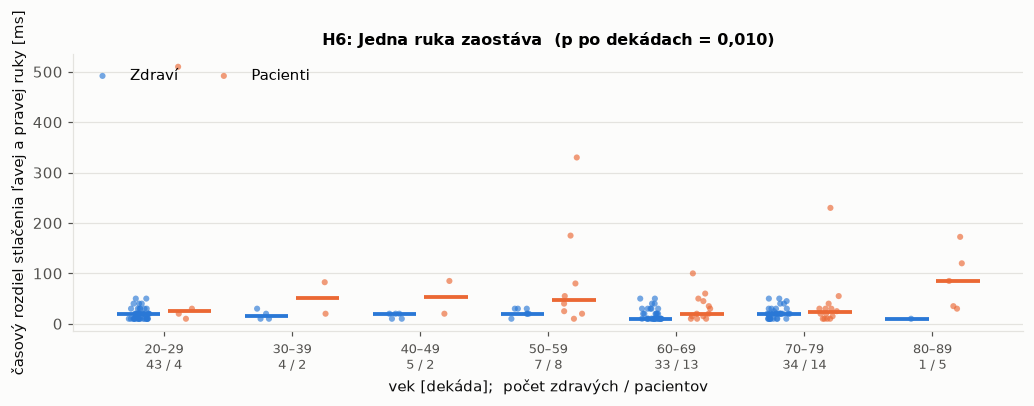

dekáda,zdraví n,zdraví medián,pacienti n,pacienti medián,p v dekáde
20–29,43,"20,00",4,"25,00","0,297"
30–39,4,"15,00",2,"51,25",–
40–49,5,"20,00",2,"52,50",–
50–59,7,"20,00",8,"47,50","0,113"
60–69,33,"10,00",13,"20,00","0,055"
70–79,34,"20,00",14,"22,50","0,476"
80–89,1,"10,00",5,"85,00",–


**Výsledok: ✅ potvrdená** – pri porovnaní rovnako starých ľudí p = 0,010; pacienti sú horší v 6 z 6 dekád.

In [3]:
rng = np.random.default_rng(0)


def show_hypothesis(k, hypothesis):
    test, p, title, text, label = hypothesis
    m = TESTS[test]["main"]
    display(Markdown(f"### H{k}: {title}\n\n{text}\n\n*Test {test}.*"))
    decades = [d for d in AGE_CATEGORY_LABELS
               if ((m.decade == d) & (m.group == "control")).any() and ((m.decade == d) & (m.group == "patient")).any()]
    fig, ax = plt.subplots(figsize=(9.5, 3.6))
    for x, decade in enumerate(decades):
        for shift, group in [(-0.2, "control"), (0.2, "patient")]:
            v = scaled(p, m.loc[(m.decade == decade) & (m.group == group), p].dropna())
            ax.scatter(x + shift + rng.uniform(-0.09, 0.09, len(v)), v, s=16, color=GROUP_COLORS[group], alpha=0.65,
                       edgecolor="none", label=SK_GROUP[group] if x == 0 else None)
            if len(v):
                ax.hlines(v.median(), x + shift - 0.17, x + shift + 0.17, color=GROUP_COLORS[group], lw=2.5)
    counts = [f"{d}\n{int(((m.decade == d) & (m.group == 'control')).sum())} / "
              f"{int(((m.decade == d) & (m.group == 'patient')).sum())}" for d in decades]
    ax.set_xticks(range(len(decades)), counts, fontsize=8.5)
    ax.set_xlabel("vek [dekáda];  počet zdravých / pacientov")
    ax.grid(axis="x", visible=False)
    if p in LOG_AXIS:
        log_axis(ax)
    ax.set_ylabel(label)
    ax.legend(loc="upper left", ncol=2)
    ax.set_title(f"H{k}: {title}  (p po dekádach {peq(DECADE_TESTS.loc[p, 'p_holm'])})")
    save(fig, f"H{k:02d}_{p}")
    d = decade_rows(test, p)
    display(d.assign(**{"zdraví medián": d["zdraví medián"].map(fmt), "pacienti medián": d["pacienti medián"].map(fmt),
                        "p v dekáde": d["p v dekáde"].map(lambda v: "–" if np.isnan(v) else pval(v))})
            .style.hide(axis="index"))
    d2 = d.loc[(d["zdraví n"] >= 2) & (d["pacienti n"] >= 2)]
    worse = int((np.sign(d2["pacienti medián"] - d2["zdraví medián"]) == DECADE_TESTS.loc[p, "expected"]).sum())
    display(Markdown(f"**Výsledok: ✅ potvrdená** – pri porovnaní rovnako starých ľudí p {peq(DECADE_TESTS.loc[p, 'p_holm'])}; "
                     f"pacienti sú horší v {worse} z {len(d2)} dekád."))


for k, hypothesis in enumerate(CONFIRMED, 1):
    show_hypothesis(k, hypothesis)

In [4]:
display(Markdown("**Testovali sme aj, ale nepotvrdilo sa** (pri rovnakom veku sa zdraví a pacienti nelíšia): "
                 + "; ".join(f"{title.lower()} ({test})" for test, p, title, *_ in NOT_CONFIRMED) + "."))

**Testovali sme aj, ale nepotvrdilo sa** (pri rovnakom veku sa zdraví a pacienti nelíšia): väčšie rozdiely medzi prstami (EXACT_FORCE); jedna ruka sa chveje viac (EXACT_FORCE); pomalšie chvenie (EXACT_FORCE); nepravidelný rytmus (RYTMUS).

## 2. Zmeny parametrov s vekom u zdravých

### Mení sa výkon zdravých ľudí s vekom?

Skúmame, či majú starší zdraví ľudia iné hodnoty ako mladší (napr. silnejšie chvenie alebo pomalšie stláčanie).
Predpokladáme, že s vekom sa výkon mierne zhoršuje.

*Iba zdraví. Spearmanova korelácia s vekom (ρ: 0 = žiadna súvislosť, ±1 = úplná), p opravené Holmovou korekciou.*

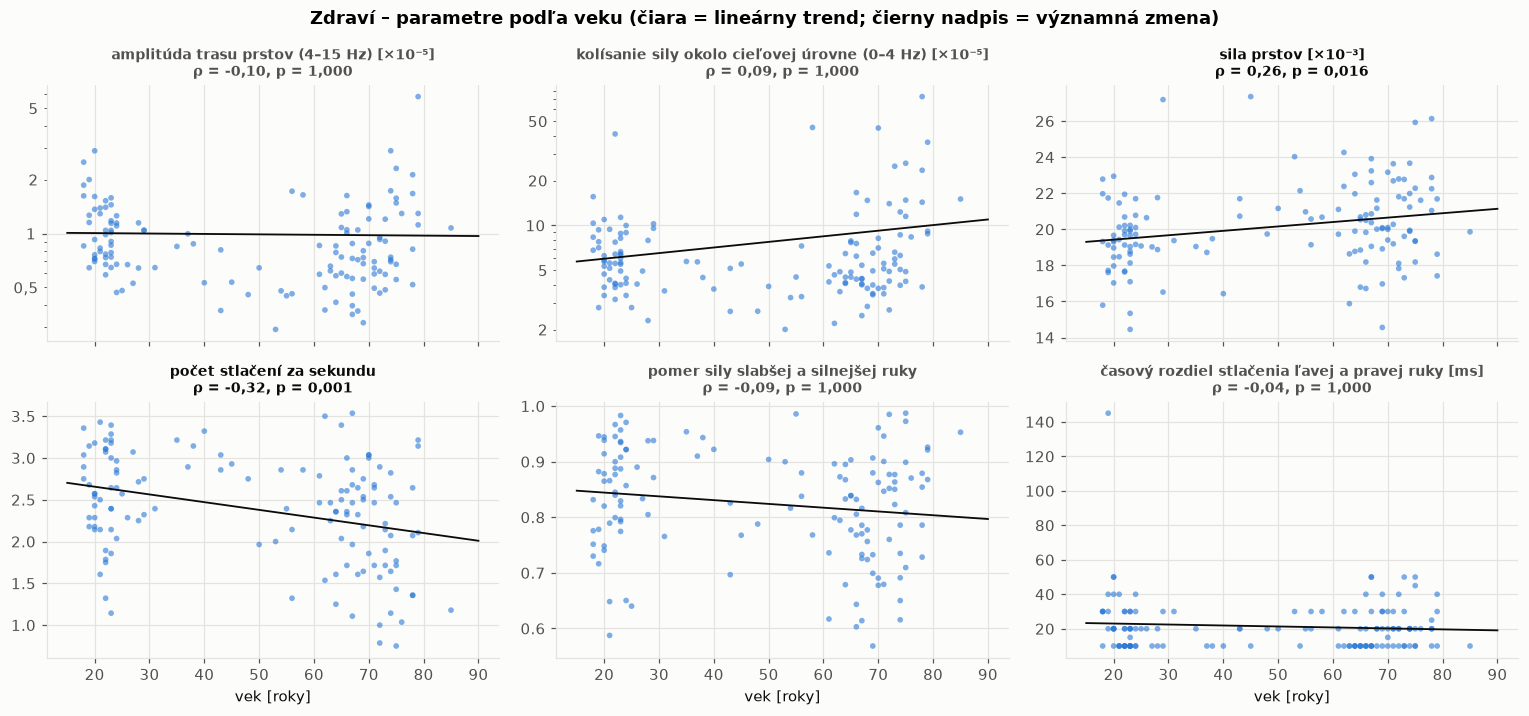

test,parameter,ρ,p (Holm),zmena za 10 rokov,mení sa s vekom
EXACT_FORCE,amplitúda trasu prstov (4–15 Hz) [×10⁻⁵],"-0,10","1,000","-0,0054",nie
EXACT_FORCE,kolísanie sily okolo cieľovej úrovne (0–4 Hz) [×10⁻⁵],"0,09","1,000","0,70",nie
EXACT_FORCE,sila prstov [×10⁻³],"0,26","0,016","0,24",áno
RYTMUS,počet stlačení za sekundu,"-0,32","0,001","-0,09",áno
RYTMUS,pomer sily slabšej a silnejšej ruky,"-0,09","1,000","-0,0068",nie
RYTMUS,časový rozdiel stlačenia ľavej a pravej ruky [ms],"-0,04","1,000","-0,56",nie


**Výsledok: čiastočne áno.** Po korekcii sa s vekom významne mení 2 z 6 parametrov (sila prstov [×10⁻³], počet stlačení za sekundu). Všetky trendy sú slabé (najväčšie |ρ| = 0,32).

**Obmedzenie:** zdraví sú hlavne v dekádach 20–29, 60–69, 70–79 (aspoň 20 osôb); v ostatných dekádach je ich málo, preto sa malá zmena s vekom nedá vylúčiť. Zdraví nad 60 rokov sú navyše takmer všetci z meraní v meracom centre (9. 9. a 9.–13. 11. 2026), mladší z iných meraní, takže vek sa čiastočne prekrýva s miestom merania.

In [5]:
ncols = 3
fig, axes = plt.subplots(int(np.ceil(len(CONFIRMED) / ncols)), ncols, figsize=(14, 3.3 * np.ceil(len(CONFIRMED) / ncols)),
                         sharex=True, squeeze=False)
rows = []
for ax, (test, p, *_rest) in zip(axes.flat, CONFIRMED):
    t = TESTS[test]
    healthy = t["main"].loc[t["main"].group == "control"]
    tr = t["age_trends"].set_index("parameter").loc[p]
    y = scaled(p, healthy[p])
    ax.scatter(healthy.age, y, s=14, color=GROUP_COLORS["control"], alpha=0.6, edgecolor="none")
    ok = y.notna()
    fit = np.polyfit(healthy.age[ok], y[ok], 1)
    x = np.array([15, 90]); ax.plot(x, np.polyval(fit, x), color=TEXT, lw=1.2)
    if p in LOG_AXIS:
        log_axis(ax)
    significant = tr.spearman_p_holm < 0.05
    ax.set_title(f"{LABEL[p]}\nρ = {fmt(tr.spearman_rho)}, p {peq(tr.spearman_p_holm)}", fontsize=9,
                 color=TEXT if significant else MUTED)
    rows.append({"test": test, "parameter": LABEL[p], "ρ": fmt(tr.spearman_rho), "p (Holm)": pval(tr.spearman_p_holm),
                 "zmena za 10 rokov": fmt(scaled(p, tr.change_per_10y)),
                 "mení sa s vekom": "áno" if significant else "nie"})
for ax in axes[-1]:
    ax.set_xlabel("vek [roky]")
fig.suptitle("Zdraví – parametre podľa veku (čiara = lineárny trend; čierny nadpis = významná zmena)",
             fontweight="bold")
save(fig, "vek_zdravi")
age_table = pd.DataFrame(rows)
display(age_table.style.hide(axis="index"))
changing = age_table.loc[age_table["mení sa s vekom"] == "áno", "parameter"].tolist()
healthy_per_decade = TESTS["EXACT_FORCE"]["main"].query("group == 'control'").decade.value_counts()
big_decades = [d for d in AGE_CATEGORY_LABELS if healthy_per_decade.get(d, 0) >= 20]
display(Markdown(
    ("**Výsledok: nepotvrdilo sa.** " if not changing else "**Výsledok: čiastočne áno.** ")
    + f"Po korekcii sa s vekom významne mení {len(changing)} z {len(age_table)} parametrov"
    + (f" ({', '.join(changing)})" if changing else "")
    + f". Všetky trendy sú slabé (najväčšie |ρ| = {fmt(age_table['ρ'].str.replace(',', '.').astype(float).abs().max())}).\n\n"
    + f"**Obmedzenie:** zdraví sú hlavne v dekádach {', '.join(big_decades)} (aspoň 20 osôb); v ostatných dekádach "
    "je ich málo, preto sa malá zmena s vekom nedá vylúčiť. Zdraví nad 60 rokov sú navyše takmer všetci z meraní "
    "v meracom centre (9. 9. a 9.–13. 11. 2026), mladší z iných meraní, takže vek sa čiastočne prekrýva s miestom merania."))

## 3. Normálne hodnoty podľa dekád

**Ako je norma stanovená:** pre každú dekádu (10–19, 20–29, …) zvlášť, **iba z meraní zdravých ľudí v tejto dekáde**.
- *Typická hodnota* = medián zdravých v dekáde.
- *Normálny rozsah* = hodnoty, do ktorých patrí 95 % zdravých v dekáde (2,5 % až 97,5 % kvantil).
- **Pozor na počet ľudí:** v niektorých dekádach je zdravých veľmi málo (napr. 30–39 rokov len 4 osoby). Pri takom
  malom počte je rozsah prakticky od najmenšej po najväčšiu nameranú hodnotu a treba ho brať len orientačne.
  Stĺpec *spoľahlivosť* to vyznačuje: **dobrá** (≥ 20 zdravých), **orientačná** (10–19), **slabá** (3–9);
  pri menej ako 3 zdravých sa rozsah nedá určiť.

V tabuľke je pre porovnanie aj to, aké hodnoty majú **pacienti** v tej istej dekáde – medián, kde leží polovica
pacientov (25–75 %), a koľko pacientov je mimo normy zdravých svojej dekády.

In [6]:
from rehapiano.common.stats.group_analysis import decade_norms

MIN_DECADE_SIZE = 3  # below this a range cannot be estimated at all

# What the Y axis of every norm panel means (Slovak, shown above each table).
NORM_DESCRIPTION = {
    "tremor_amplitude": "o koľko sa sila prsta rýchlo mení hore a dole (4–15 Hz), teda ako silno sa prst trasie. "
                        "Je to priemerná amplitúda trasu zo spektrogramu, nie frekvencia; medián prstov ruky, "
                        "priemer oboch rúk. Väčšie číslo = silnejší tras.",
    "movement_amplitude": "o koľko sa držaná sila pomaly odchyľuje hore a dole od úrovne, ktorú chce človek udržať "
                          "(0–4 Hz, samotná výška sily je odstránená). Väčšie číslo = menej stabilne držaná sila.",
    "finger_spread": "pre každý prst sa vypočíta pomer trasu (4–15 Hz) a kolísania sily (0–4 Hz) a porovná sa medzi "
                     "prstami jednej ruky (smerodajná odchýlka / priemer). 0 = všetky prsty sa správajú rovnako, "
                     "väčšie číslo = prsty sa správajú odlišne. Bez jednotky.",
    "press_rate_hz": "koľko stlačení urobí človek za jednu sekundu. Väčšie číslo = rýchlejšie stláčanie.",
    "balance": "veľkosť stlačenia slabšej ruky delená veľkosťou stlačenia silnejšej ruky. 1 = obe ruky tlačia "
               "rovnako, 0,5 = slabšia ruka tlačí len polovičnou silou.",
    "sync_lag_ms": "o koľko milisekúnd neskôr dosiahne jedna ruka vrchol stlačenia ako druhá (medián stlačení). "
                   "0 = obe ruky naraz; meria sa po 10 ms.",
    "mean_force": "priemerná sila, ktorou človek drží prsty pri teste (medián aktívnych prstov ruky, priemer oboch "
                  "rúk). Väčšie číslo = silnejší tlak.",
    "tremor_balance": "chvenie pokojnejšej ruky delené chvením horšej ruky. 1 = obe ruky sa chvejú rovnako, "
                      "0,5 = horšia ruka sa chveje dvakrát viac.",
    "tremor_frequency_hz": "frekvencia najvýraznejšieho chvenia prstov v pásme 4–15 Hz (medián prstov ruky, priemer "
                           "oboch rúk). Menšie číslo = pomalšie chvenie.",
    "interval_cv": "ako veľmi sa menia časy medzi po sebe idúcimi stlačeniami (smerodajná odchýlka / priemer). "
                   "0 = úplne pravidelný rytmus, väčšie číslo = nepravidelnejší rytmus.",
}


def reliability(n):
    if n < MIN_DECADE_SIZE:
        return "nedá sa určiť"
    return "dobrá" if n >= 20 else "orientačná" if n >= 10 else "slabá"


def norms_for(test, p):
    # 2.5 / 50 / 97.5 % of the healthy people in each decade only
    m = TESTS[test]["main"]
    table = decade_norms(m.loc[m.group == "control"], [p], min_size=MIN_DECADE_SIZE).set_index("decade")
    return table.assign(low=scaled(p, table.p2_5), mid=scaled(p, table["median"]), high=scaled(p, table.p97_5))


def norm_table(test, p):
    m = TESTS[test]["main"]
    norms = norms_for(test, p)
    rows = []
    for decade in AGE_CATEGORY_LABELS:
        s = scaled(p, m.loc[(m.decade == decade) & (m.group == "patient"), p].dropna())
        n_h = int(norms.loc[decade, "n"])
        if n_h == 0 and s.empty:
            continue
        low, high = norms.loc[decade, "low"], norms.loc[decade, "high"]
        has_norm = not np.isnan(low)
        outside = int(((s < low) | (s > high)).sum()) if has_norm else None
        rows.append({
            "dekáda": decade,
            "zdraví n": n_h,
            "TYPICKÁ hodnota zdravých": fmt(norms.loc[decade, "mid"]) if n_h else "–",
            "NORMÁLNY ROZSAH zdravých": f"{fmt(low)} – {fmt(high)}" if has_norm else "–",
            "spoľahlivosť": reliability(n_h),
            "pacienti n": len(s), "pacienti medián": fmt(s.median()) if len(s) else "–",
            "pacienti 25–75 %": f"{fmt(s.quantile(.25))} – {fmt(s.quantile(.75))}" if len(s) >= 4 else "–",
            "pacienti mimo normy": f"{outside} z {len(s)}" if has_norm and len(s) else "–",
        })
    return pd.DataFrame(rows)


def norm_figure(test, parameters, name):
    m = TESTS[test]["main"]
    decades = [d for d in AGE_CATEGORY_LABELS if (m.decade == d).any()]
    ncols = 3 if len(parameters) % 3 == 0 else 2
    nrows = int(np.ceil(len(parameters) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.6 * nrows), squeeze=False)
    for ax, p in zip(axes.flat, parameters):
        norms = norms_for(test, p)
        for k, decade in enumerate(decades):
            low, mid, high, n = norms.loc[decade, ["low", "mid", "high", "n"]]
            if not np.isnan(low):
                # weak decades (few healthy people) are drawn lighter
                alpha = 0.22 if n >= 10 else 0.09
                ax.add_patch(plt.Rectangle((k - 0.4, low), 0.8, high - low, color=GROUP_COLORS["control"],
                                           alpha=alpha, lw=0))
            if n:
                ax.hlines(mid, k - 0.4, k + 0.4, color=GROUP_COLORS["control"], lw=1.5)
            for shift, group in [(-0.15, "control"), (0.15, "patient")]:
                v = scaled(p, m.loc[(m.decade == decade) & (m.group == group), p].dropna())
                ax.scatter(k + shift + rng.uniform(-0.08, 0.08, len(v)), v, s=11, color=GROUP_COLORS[group],
                           alpha=0.7, edgecolor="none")
        ax.set_xticks(range(len(decades)), [f"{d}\nn={int(norms.loc[d, 'n'])}" for d in decades], fontsize=8.5)
        ax.set_xlim(-0.6, len(decades) - 0.4)
        ax.grid(axis="x", visible=False)
        if p in LOG_AXIS:
            log_axis(ax)
        ax.set_title(LABEL[p], fontsize=10)
        ax.set_xlabel("vek [dekáda], n = počet zdravých")
    for ax in axes.flat[len(parameters):]:
        ax.axis("off")
    handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS["control"], alpha=0.3),
               plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS["control"], alpha=0.12),
               plt.Line2D([], [], color=GROUP_COLORS["control"], lw=1.5),
               plt.Line2D([], [], marker="o", ls="", color=GROUP_COLORS["control"]),
               plt.Line2D([], [], marker="o", ls="", color=GROUP_COLORS["patient"])]
    fig.legend(handles, ["normálny rozsah (≥ 10 zdravých)", "normálny rozsah – len orientačne (3–9 zdravých)",
                         "typická hodnota zdravých (medián)", "zdravý človek", "pacient"],
               loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.05),
               fontsize=9 if ncols == 2 else 10)
    fig.suptitle(f"{test}: normálne hodnoty zdravých v každej dekáde", fontweight="bold",
                 y=1.13)
    save(fig, name)


def show_norms(test):
    parameters = [p for t, p, *_ in CONFIRMED if t == test]
    norm_figure(test, parameters, f"normy_{test.lower()}")
    for p in parameters:
        display(Markdown(f"**{LABEL[p]}** – {NORM_DESCRIPTION.get(p, '')}"))
        display(norm_table(test, p).style.hide(axis="index"))

### Test EXACT_FORCE

**Čo je na osi Y:** snímače RehaPiana nie sú kalibrované v newtonoch, preto sú sila a amplitúdy v **jednotkách
zariadenia** (rovnaké pre všetkých, dajú sa navzájom porovnávať). Malé čísla sú kvôli čitateľnosti vynásobené
(×10⁻⁵ = hodnota je v stotisícinách).
Pod každým grafom je krátky popis, čo parameter znamená.

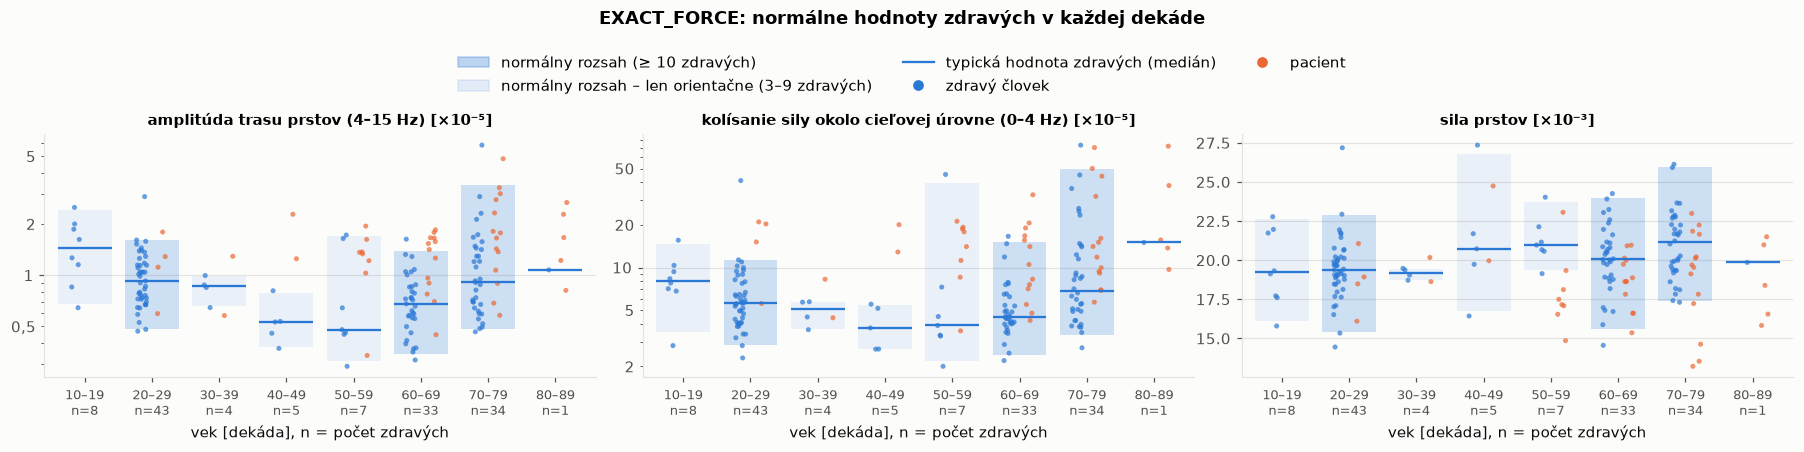

**amplitúda trasu prstov (4–15 Hz) [×10⁻⁵]** – o koľko sa sila prsta rýchlo mení hore a dole (4–15 Hz), teda ako silno sa prst trasie. Je to priemerná amplitúda trasu zo spektrogramu, nie frekvencia; medián prstov ruky, priemer oboch rúk. Väčšie číslo = silnejší tras.

dekáda,zdraví n,TYPICKÁ hodnota zdravých,NORMÁLNY ROZSAH zdravých,spoľahlivosť,pacienti n,pacienti medián,pacienti 25–75 %,pacienti mimo normy
10–19,8,"1,44","0,68 – 2,42",slabá,0,–,–,–
20–29,43,"0,93","0,48 – 1,61",dobrá,4,"1,20","0,98 – 1,41",1 z 4
30–39,4,"0,86","0,66 – 0,99",slabá,2,"0,94",–,2 z 2
40–49,5,"0,53","0,38 – 0,78",slabá,2,"1,77",–,2 z 2
50–59,7,"0,48","0,32 – 1,71",slabá,8,"1,35","1,17 – 1,43",1 z 8
60–69,33,"0,68","0,35 – 1,38",dobrá,13,"1,42","0,90 – 1,65",7 z 13
70–79,34,"0,92","0,48 – 3,41",dobrá,14,"1,71","1,15 – 2,66",1 z 14
80–89,1,"1,07",–,nedá sa určiť,5,"1,66","1,22 – 2,28",–


**kolísanie sily okolo cieľovej úrovne (0–4 Hz) [×10⁻⁵]** – o koľko sa držaná sila pomaly odchyľuje hore a dole od úrovne, ktorú chce človek udržať (0–4 Hz, samotná výška sily je odstránená). Väčšie číslo = menej stabilne držaná sila.

dekáda,zdraví n,TYPICKÁ hodnota zdravých,NORMÁLNY ROZSAH zdravých,spoľahlivosť,pacienti n,pacienti medián,pacienti 25–75 %,pacienti mimo normy
10–19,8,"8,06","3,51 – 14,68",slabá,0,–,–,–
20–29,43,"5,59","2,83 – 11,31",dobrá,4,"17,74","12,75 – 20,49",3 z 4
30–39,4,"5,08","3,70 – 5,73",slabá,2,"6,34",–,1 z 2
40–49,5,"3,74","2,65 – 5,47",slabá,2,"16,47",–,2 z 2
50–59,7,"3,90","2,20 – 39,71",slabá,8,"15,96","10,55 – 18,85",0 z 8
60–69,33,"4,50","2,43 – 15,11",dobrá,13,"10,51","7,08 – 16,76",5 z 13
70–79,34,"6,84","3,34 – 49,98",dobrá,14,"12,96","9,19 – 27,89",2 z 14
80–89,1,"15,03",–,nedá sa určiť,5,"15,66","13,73 – 37,95",–


**sila prstov [×10⁻³]** – priemerná sila, ktorou človek drží prsty pri teste (medián aktívnych prstov ruky, priemer oboch rúk). Väčšie číslo = silnejší tlak.

dekáda,zdraví n,TYPICKÁ hodnota zdravých,NORMÁLNY ROZSAH zdravých,spoľahlivosť,pacienti n,pacienti medián,pacienti 25–75 %,pacienti mimo normy
10–19,8,"19,22","16,11 – 22,64",slabá,0,–,–,–
20–29,43,"19,39","15,40 – 22,89",dobrá,4,"18,71","17,89 – 19,46",0 z 4
30–39,4,"19,21","18,74 – 19,47",slabá,2,"19,40",–,2 z 2
40–49,5,"20,72","16,76 – 26,79",slabá,2,"22,36",–,0 z 2
50–59,7,"20,97","19,36 – 23,74",slabá,8,"17,33","16,95 – 18,42",7 z 8
60–69,33,"20,09","15,61 – 23,98",dobrá,13,"18,64","17,82 – 19,99",1 z 13
70–79,34,"21,13","17,40 – 25,96",dobrá,14,"19,62","17,38 – 21,30",4 z 14
80–89,1,"19,86",–,nedá sa určiť,5,"18,39","16,55 – 20,98",–


In [7]:
show_norms("EXACT_FORCE")

### Test RYTMUS

**Čo je na osi Y:** pod grafom je pri každom parametri krátky popis.

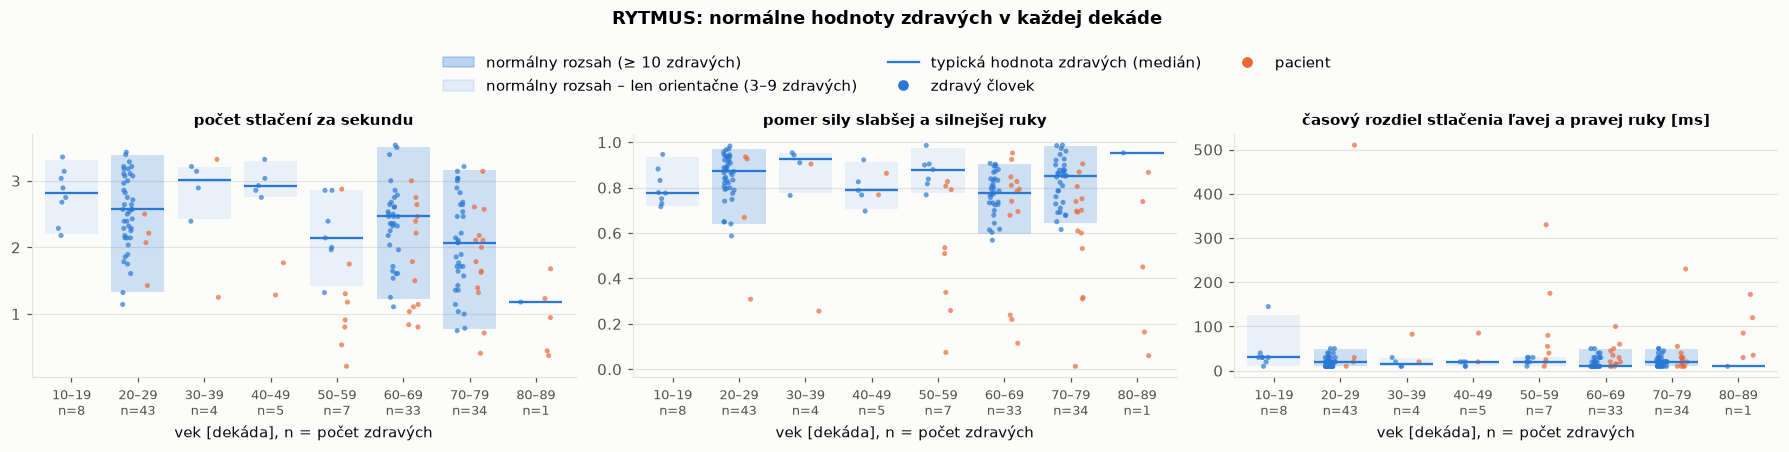

**počet stlačení za sekundu** – koľko stlačení urobí človek za jednu sekundu. Väčšie číslo = rýchlejšie stláčanie.

dekáda,zdraví n,TYPICKÁ hodnota zdravých,NORMÁLNY ROZSAH zdravých,spoľahlivosť,pacienti n,pacienti medián,pacienti 25–75 %,pacienti mimo normy
10–19,8,"2,82","2,20 – 3,32",slabá,0,–,–,–
20–29,43,"2,57","1,34 – 3,39",dobrá,4,"2,14","1,91 – 2,29",0 z 4
30–39,4,"3,02","2,43 – 3,21",slabá,2,"2,29",–,2 z 2
40–49,5,"2,93","2,76 – 3,29",slabá,2,"1,53",–,2 z 2
50–59,7,"2,14","1,42 – 2,86",slabá,8,"1,04","0,74 – 1,42",7 z 8
60–69,33,"2,46","1,22 – 3,51",dobrá,13,"1,79","1,11 – 2,46",5 z 13
70–79,34,"2,07","0,78 – 3,16",dobrá,14,"1,89","1,45 – 2,16",2 z 14
80–89,1,"1,18",–,nedá sa určiť,5,"0,95","0,45 – 1,23",–


**pomer sily slabšej a silnejšej ruky** – veľkosť stlačenia slabšej ruky delená veľkosťou stlačenia silnejšej ruky. 1 = obe ruky tlačia rovnako, 0,5 = slabšia ruka tlačí len polovičnou silou.

dekáda,zdraví n,TYPICKÁ hodnota zdravých,NORMÁLNY ROZSAH zdravých,spoľahlivosť,pacienti n,pacienti medián,pacienti 25–75 %,pacienti mimo normy
10–19,8,"0,78","0,72 – 0,94",slabá,0,–,–,–
20–29,43,"0,87","0,64 – 0,97",dobrá,4,"0,80","0,58 – 0,93",1 z 4
30–39,4,"0,93","0,78 – 0,95",slabá,2,"0,58",–,1 z 2
40–49,5,"0,79","0,70 – 0,91",slabá,2,"0,82",–,0 z 2
50–59,7,"0,88","0,78 – 0,97",slabá,8,"0,52","0,32 – 0,80",5 z 8
60–69,33,"0,78","0,60 – 0,90",dobrá,13,"0,78","0,68 – 0,83",5 z 13
70–79,34,"0,85","0,64 – 0,99",dobrá,14,"0,69","0,55 – 0,75",6 z 14
80–89,1,"0,95",–,nedá sa určiť,5,"0,45","0,16 – 0,74",–


**časový rozdiel stlačenia ľavej a pravej ruky [ms]** – o koľko milisekúnd neskôr dosiahne jedna ruka vrchol stlačenia ako druhá (medián stlačení). 0 = obe ruky naraz; meria sa po 10 ms.

dekáda,zdraví n,TYPICKÁ hodnota zdravých,NORMÁLNY ROZSAH zdravých,spoľahlivosť,pacienti n,pacienti medián,pacienti 25–75 %,pacienti mimo normy
10–19,8,"30,00","11,75 – 126,63",slabá,0,–,–,–
20–29,43,"20,00","10,00 – 49,50",dobrá,4,"25,00","17,50 – 150,00",1 z 4
30–39,4,"15,00","10,00 – 29,25",slabá,2,"51,25",–,1 z 2
40–49,5,"20,00","10,00 – 20,00",slabá,2,"52,50",–,1 z 2
50–59,7,"20,00","11,50 – 30,00",slabá,8,"47,50","23,75 – 103,75",6 z 8
60–69,33,"10,00","10,00 – 50,00",dobrá,13,"20,00","15,00 – 45,00",2 z 13
70–79,34,"20,00","10,00 – 50,00",dobrá,14,"22,50","11,25 – 30,00",2 z 14
80–89,1,"10,00",–,nedá sa určiť,5,"85,00","35,00 – 120,00",–


In [8]:
show_norms("RYTMUS")

In [9]:
healthy_per_decade = TESTS["EXACT_FORCE"]["main"].query("group == 'control'").decade.value_counts()
reliable = [f"{d} ({healthy_per_decade[d]} zdravých)" for d in AGE_CATEGORY_LABELS if healthy_per_decade.get(d, 0) >= 20]
few = [d for d in AGE_CATEGORY_LABELS if 0 < healthy_per_decade.get(d, 0) < 20]
display(Markdown(
    "**Ako normu použiť:** hodnota nového človeka sa porovná s rozsahom jeho dekády. Hodnota mimo rozsahu je neobvyklá "
    "(mimo neho je len 5 % zdravých). Spoľahlivá (aspoň 20 zdravých) je zatiaľ norma pre " + ", ".join(reliable)
    + "; pre dekády " + ", ".join(few) + " treba **namerať viac zdravých ľudí**."))

**Ako normu použiť:** hodnota nového človeka sa porovná s rozsahom jeho dekády. Hodnota mimo rozsahu je neobvyklá (mimo neho je len 5 % zdravých). Spoľahlivá (aspoň 20 zdravých) je zatiaľ norma pre 20–29 (43 zdravých), 60–69 (33 zdravých), 70–79 (34 zdravých); pre dekády 10–19, 30–39, 40–49, 50–59, 80–89 treba **namerať viac zdravých ľudí**.

## 4. Doplnková hypotéza

Nie je porovnaním zdravých a pacientov, ale hovorí, či normy treba deliť podľa pohlavia.

### D1: Muži a ženy majú rovnaké hodnoty

Skúmame, či sa zdraví muži a ženy líšia (napr. v sile alebo v tempe). Predpokladáme, že nie – potom normálne
hodnoty nemusia byť zvlášť pre mužov a pre ženy.

*Iba zdraví. Lineárny model parameter = vek + pohlavie; rozdiel muži − ženy v smerodajných odchýlkach (SD).*

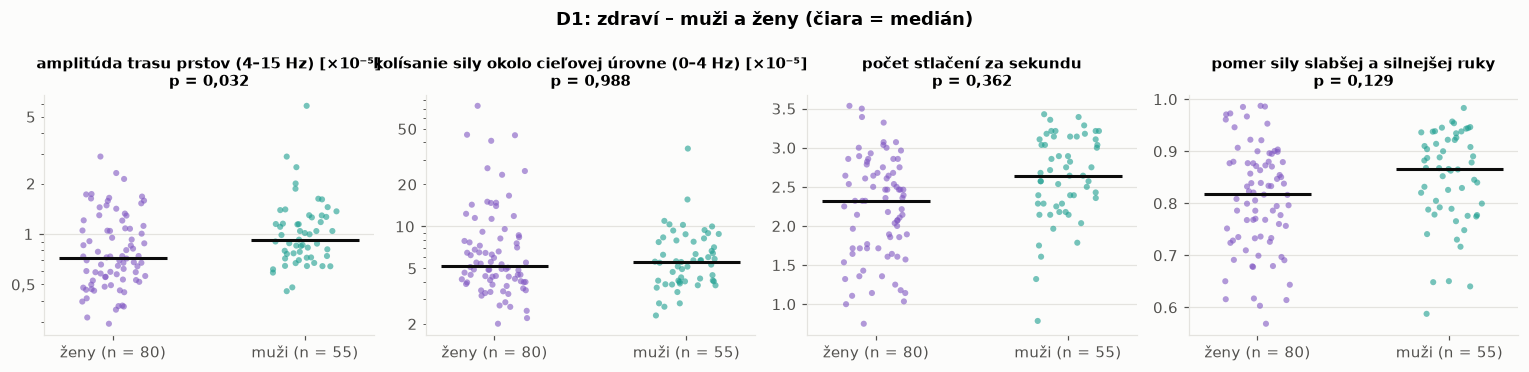

test,parameter,muži n,ženy n,medián muži,medián ženy,rozdiel pri rovnakom veku [SD],p,p (Holm)
EXACT_FORCE,amplitúda trasu prstov (4–15 Hz) [×10⁻⁵],55,80,"0,93","0,72","0,69","0,032","0,191"
EXACT_FORCE,kolísanie sily okolo cieľovej úrovne (0–4 Hz) [×10⁻⁵],55,80,"5,59","5,23","0,0046","0,988","0,988"
EXACT_FORCE,sila prstov [×10⁻³],55,80,"19,39","20,51","-0,23","0,317","0,950"
RYTMUS,počet stlačení za sekundu,55,80,"2,64","2,32","0,27","0,362","0,950"
RYTMUS,pomer sily slabšej a silnejšej ruky,55,80,"0,87","0,82","0,31","0,129","0,545"
RYTMUS,časový rozdiel stlačenia ľavej a pravej ruky [ms],55,80,"20,00","20,00","0,27","0,109","0,545"


**Výsledok: ✅ potvrdená** – po Holmovej korekcii sa muži a ženy nelíšia v žiadnom parametri (najmenšie neopravené p = 0,032). Normy preto netreba deliť podľa pohlavia. **Obmedzenie:** mužov je 55 a žien 80, malý rozdiel (napr. v sile) sa nedá vylúčiť.

In [10]:
rows = []
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
SEX = {"female": "ženy", "male": "muži"}
SEX_COLORS = {"female": "#7f56c2", "male": "#1c9e8f"}
SEX_PLOTS = ["tremor_amplitude", "movement_amplitude", "press_rate_hz", "balance"]
for k, (test, p, *_rest) in enumerate(CONFIRMED):
    t = TESTS[test]
    h = t["main"].loc[(t["main"].group == "control") & t["main"].gender.isin(SEX)].dropna(subset=[p])
    y = h[p] / h[p].std() if p not in LOG_AXIS else np.log10(h[p]) / np.log10(h[p]).std()
    male = (h.gender == "male").astype(float)
    model = ols(y, np.c_[np.ones(len(h)), h.age / 10, male], ["b0", "vek", "muž"]).set_index("term").loc["muž"]
    rows.append({"test": test, "parameter": LABEL[p], "muži n": int(male.sum()), "ženy n": int(len(h) - male.sum()),
                 "medián muži": fmt(scaled(p, h.loc[male == 1, p].median())),
                 "medián ženy": fmt(scaled(p, h.loc[male == 0, p].median())),
                 "rozdiel pri rovnakom veku [SD]": fmt(model.coefficient), "p": model.p})
    if p in SEX_PLOTS:
        ax = axes[SEX_PLOTS.index(p)]
        for j, sex in enumerate(SEX):
            v = scaled(p, h.loc[h.gender == sex, p])
            ax.scatter(j + rng.uniform(-0.17, 0.17, len(v)), v, s=16, color=SEX_COLORS[sex], alpha=0.6, edgecolor="none")
            ax.hlines(v.median(), j - 0.28, j + 0.28, color=TEXT, lw=2)
        ax.set_xticks([0, 1], [f"{SEX[s]} (n = {int((h.gender == s).sum())})" for s in SEX]); ax.grid(axis="x", visible=False)
        if p in LOG_AXIS:
            log_axis(ax)
        ax.set_title(f"{LABEL[p]}\np {peq(model.p)}", fontsize=9.5)
fig.suptitle("D1: zdraví – muži a ženy (čiara = medián)", fontweight="bold")
save(fig, "D1_pohlavie")
sex = pd.DataFrame(rows)
sex["p (Holm)"] = np.minimum(1, np.maximum.accumulate(np.sort(sex.p) * (len(sex) - np.arange(len(sex)))))[
    np.argsort(np.argsort(sex.p))]
display(sex.assign(p=sex.p.map(pval), **{"p (Holm)": sex["p (Holm)"].map(pval)}).style.hide(axis="index"))
display(Markdown(
    f"**Výsledok: ✅ potvrdená** – po Holmovej korekcii sa muži a ženy nelíšia v žiadnom parametri "
    f"(najmenšie neopravené p {peq(sex.p.min())}). Normy preto netreba deliť podľa pohlavia. "
    f"**Obmedzenie:** mužov je {sex['muži n'].iloc[0]} a žien {sex['ženy n'].iloc[0]}, malý rozdiel (napr. v sile) "
    "sa nedá vylúčiť."))

## Záver

In [11]:
lines = [f"- **H{k}** {title} ({test})" for k, (test, p, title, *_r) in enumerate(CONFIRMED, 1)]
age_text = ("žiadny parameter sa po oprave na počet testov s vekom preukázateľne nemení." if not changing else
            f"po oprave na počet testov sa s vekom mení {len(changing)} z {len(age_table)} parametrov "
            f"({', '.join(changing)}); trendy sú slabé.")
sex_text = ("pohlavie hodnoty zdravých neovplyvňuje, normy netreba deliť na mužov a ženy."
            if (sex["p (Holm)"] >= 0.05).all() else "muži a ženy sa v niektorých parametroch líšia – pozri tabuľku D1.")
display(Markdown("**Potvrdené hypotézy (pacienti vs. rovnako starí zdraví):**\n" + "\n".join(lines) + f"""

**Vek u zdravých:** {age_text}

**Normy (časť 3):** pre každú dekádu je normálny rozsah 95 % zdravých tejto dekády. Spoľahlivá je zatiaľ norma pre
{", ".join(reliable)} – pre ostatné dekády treba namerať viac zdravých ľudí.

**Doplnková:** D1 – {sex_text}
"""))

**Potvrdené hypotézy (pacienti vs. rovnako starí zdraví):**
- **H1** Silnejšie chvenie prstov (EXACT_FORCE)
- **H2** Sila viac kolíše (EXACT_FORCE)
- **H3** Menšia sila prstov (EXACT_FORCE)
- **H4** Pomalšie stláčanie (RYTMUS)
- **H5** Jedna ruka tlačí slabšie (RYTMUS)
- **H6** Jedna ruka zaostáva (RYTMUS)

**Vek u zdravých:** po oprave na počet testov sa s vekom mení 2 z 6 parametrov (sila prstov [×10⁻³], počet stlačení za sekundu); trendy sú slabé.

**Normy (časť 3):** pre každú dekádu je normálny rozsah 95 % zdravých tejto dekády. Spoľahlivá je zatiaľ norma pre
20–29 (43 zdravých), 60–69 (33 zdravých), 70–79 (34 zdravých) – pre ostatné dekády treba namerať viac zdravých ľudí.

**Doplnková:** D1 – pohlavie hodnoty zdravých neovplyvňuje, normy netreba deliť na mužov a ženy.
